In [1]:
import os
from pathlib import Path
import logging
import pandas as pd

logging.basicConfig(
    level=logging.INFO,
    format= '%(message)s'
)

In [2]:
rank_path = Path("results/sql/metric_1.csv")
day_night_path = Path("results/sql/metric_4.csv")
workload_path = Path("results/py/top_bottom_comparison.png")
flights_amount_path = Path("results/py/day_and_night_flights.png")

if rank_path.exists():
    logging.info("Файл metric_1 найден: %s", rank_path)
else:
    logging.error("Файл metric_1 не найден: %s", rank_path)

if day_night_path.exists():
    logging.info("Файл metric_4 найден: %s", day_night_path)
else:
    logging.error("Файл metric_4 не найден: %s", day_night_path)

logging.info("Пути для сохранения: %s, %s", workload_path, flights_amount_path)

Файл metric_1 найден: results\sql\metric_1.csv
Файл metric_4 найден: results\sql\metric_4.csv
Пути для сохранения: results\py\top_bottom_comparison.png, results\py\day_and_night_flights.png


In [3]:
from scipy.stats import shapiro

rank_df = pd.read_csv(rank_path)
rank_top5 = rank_df.nlargest(5, 'total_score')
rank_bottom5 = rank_df.nsmallest(5, 'total_score')

day_night_df = pd.read_csv(day_night_path)
day_top5 = day_night_df.nlargest(5, 'day_flights')
day_bot5 = day_night_df.nsmallest(5, 'day_flights')
night_top5 = day_night_df.nlargest(5, 'night_flights')
night_bot5 = day_night_df.nsmallest(5, 'night_flights')

In [4]:
def check_normality(df, score_col):
    top5 = df.nlargest(5, score_col)
    bottom5 = df.nsmallest(5, score_col)

    stat_top, p_top = shapiro(top5[score_col])
    stat_bottom, p_bottom = shapiro(bottom5[score_col])

    logging.info("Колонка: %s", score_col)
    logging.info("  Топ-5: p-value = %.4f", p_top)
    logging.info("  Боттом-5: p-value = %.4f", p_bottom)

    if p_top > 0.05 and p_bottom > 0.05:
        logging.info("  Результат: T-test\n")
        return "t-test"
    else:
        logging.info("  Результат: Mann-Whitney U-test\n")
        return "Mann-Whitney"

In [5]:
check_normality(rank_df, 'total_score')
check_normality(day_night_df, 'day_flights')
check_normality(day_night_df, 'night_flights')

Колонка: total_score
  Топ-5: p-value = 0.1223
  Боттом-5: p-value = 0.0148
  Результат: Mann-Whitney U-test

Колонка: day_flights
  Топ-5: p-value = 0.8140
  Боттом-5: p-value = 0.0327
  Результат: Mann-Whitney U-test

Колонка: night_flights
  Топ-5: p-value = 0.9774
  Боттом-5: p-value = 0.0460
  Результат: Mann-Whitney U-test



'Mann-Whitney'

In [6]:
from scipy.stats import mannwhitneyu

def compare_mannwhitney(df, score_col):
    top = df.nlargest(5, score_col)[score_col]
    bottom = df.nsmallest(5, score_col)[score_col]

    stat, p = mannwhitneyu(top, bottom, alternative='two-sided')
    logging.info("%s: p = %.4f", score_col, p)
    return p

p_total = compare_mannwhitney(rank_df, 'total_score')
p_day = compare_mannwhitney(day_night_df, 'day_flights')
p_night = compare_mannwhitney(day_night_df, 'night_flights')

total_score: p = 0.0079
day_flights: p = 0.0109
night_flights: p = 0.0112


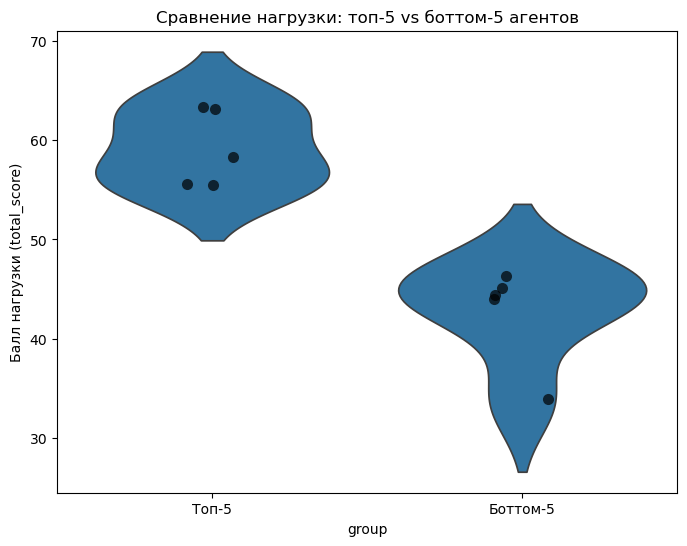

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

top5 = rank_df.nlargest(5, 'total_score').copy()
bottom5 = rank_df.nsmallest(5, 'total_score').copy()

top5['group'] = 'Топ-5'
bottom5['group'] = 'Боттом-5'

df_workload = pd.concat([top5, bottom5])

plt.figure(figsize=(8, 6))

sns.violinplot(data=df_workload, x='group', y='total_score', inner=None)
sns.stripplot(data=df_workload, x='group', y='total_score', color='black', size=8, alpha=0.7)

plt.title('Сравнение нагрузки: топ-5 vs боттом-5 агентов')
plt.ylabel('Балл нагрузки (total_score)')
plt.savefig(workload_path, dpi=150, bbox_inches='tight')
plt.show()

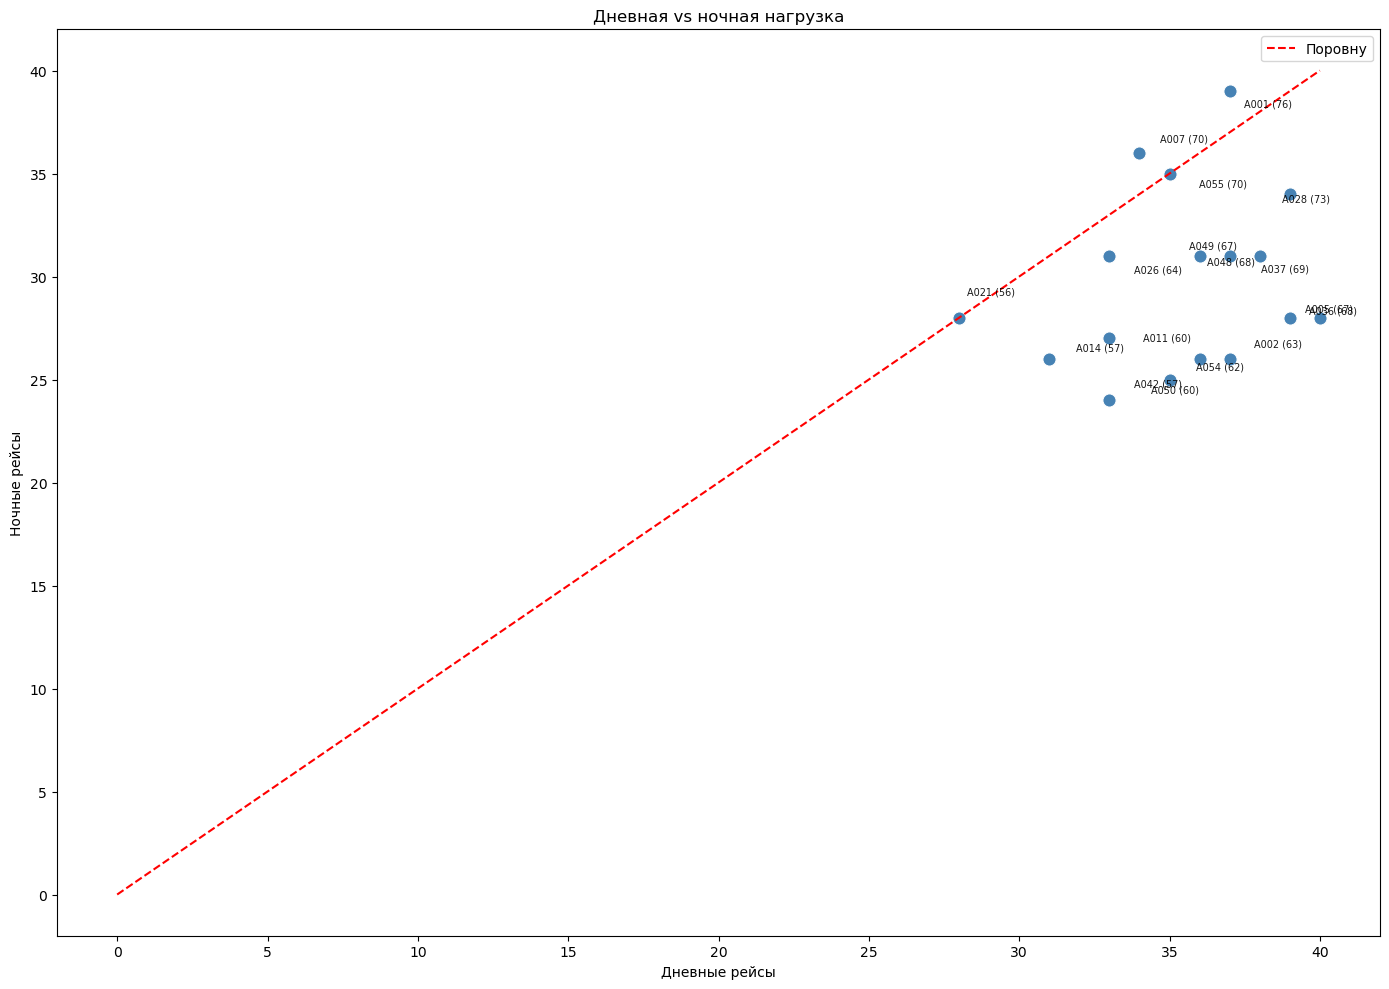

In [8]:
import random
import matplotlib.pyplot as plt
import seaborn as sns

random.seed(42)

plt.figure(figsize=(14, 10))

sns.scatterplot(
    data=day_night_df,
    x='day_flights',
    y='night_flights',
    color='steelblue',
    s=90
)

max_val = max(day_night_df['day_flights'].max(), day_night_df['night_flights'].max())
plt.plot([0, max_val], [0, max_val], color='red', linestyle='--', label='Поровну')

for _, row in day_night_df.iterrows():
    total = row['day_flights'] + row['night_flights']
    label = f"{row['agent_name']} ({total})"
    plt.text(
        row['day_flights'] + random.uniform(-0.8, 1.2),
        row['night_flights'] + random.uniform(-0.8, 1.2),
        label,
        fontsize=7,
        alpha=0.9
    )

plt.title('Дневная vs ночная нагрузка')
plt.xlabel('Дневные рейсы')
plt.ylabel('Ночные рейсы')
plt.legend()
plt.tight_layout()
plt.savefig(flights_amount_path, dpi=150, bbox_inches='tight')
plt.show()